# 12 · Paper quantum claims

**Question.** Do the paper's claims about its Hamiltonians and their preparation hold: H positive definite, the doubled space's kernel, its imaginary-time rule, and preparing the nonlinear solution?

In [1]:
from pathlib import Path

from pihm import plotting
from pihm.pipeline.results import Results

results = Results.at(Path("..").resolve())
CAMPAIGNS = ("p2_reproduction", "p4_stateprep", "p4_protocol")
plotting.apply_style()
print(results.describe(CAMPAIGNS))

p2_reproduction: 327 records, 327 ok
p4_stateprep: 231 records, 231 ok
p4_protocol: 31 records, 31 ok


In [2]:
from IPython.display import Markdown, display

from pihm.pipeline.results import reference_builds

builds = reference_builds(results.rows("p2_reproduction"))
exact = [
    row["sigma_min"] / row["hamiltonian_norm"] ** 0.5
    for (problem, variant, n), row in builds.items()
    if problem in ("R3a", "R3b") and variant == "faithful" and row["trusted"]
]
doubled = [
    row | {"paper_count": 2 ** (2 * n - 1)}
    for (problem, variant, n), row in sorted(builds.items())
    if problem.startswith("R6") and variant == "faithful"
]
protocol = [r for r in results.rows("p4_protocol") if r["status"] == "ok"]
(epsilon,) = {r["epsilon"] for r in protocol}
trusted = [r for r in protocol if r["trusted"]]
projections = [r for r in results.rows("p4_stateprep") if r["label"] == "doubled space"]
margins = [r["kernel_count"] / r["paper_count"] for r in doubled]
lines = [
    f"- H positive definite: on R3a and R3b, wherever the reference is trusted, σ_min/‖R‖ is at "
    f"most {max(exact):.1e}: an exact kernel, so H is positive semi-definite, not definite.",
    f"- The doubled space's kernel holds {min(margins):.2f} to {max(margins):.2f} times "
    "the claimed 2^(2n−1) zero eigenvalues.",
    f"- The time rule: the paper's rule reaches ε = {epsilon:g} in "
    f"{sum(r['paper_reaches_epsilon'] is True for r in protocol)} of {len(protocol)} records; on "
    f"the {len(trusted)} trusted ones its infidelity is "
    f"{min(r['paper_infidelity'] for r in trusted):.2g} to "
    f"{max(r['paper_infidelity'] for r in trusted):.2g}, its time "
    f"{min(r['gap_tau'] / r['paper_tau'] for r in trusted):.0f} to "
    f"{max(r['gap_tau'] / r['paper_tau'] for r in trusted):.0f} times shorter than the gap's.",
    f"- Preparing the nonlinear solution: from the doubled space, imaginary time reaches the "
    f"kernel's projection to {max(r['infidelity'] for r in projections):.1e}, whose fidelity "
    f"with the physical product state is {min(r['product_fidelity'] for r in projections):.3f} "
    f"to {max(r['product_fidelity'] for r in projections):.3f}: it projects, not prepares.",
]
display(Markdown("\n".join(lines)))

- H positive definite: on R3a and R3b, wherever the reference is trusted, σ_min/‖R‖ is at most 4.4e-16: an exact kernel, so H is positive semi-definite, not definite.
- The doubled space's kernel holds 1.00 to 1.88 times the claimed 2^(2n−1) zero eigenvalues.
- The time rule: the paper's rule reaches ε = 1e-06 in 0 of 31 records; on the 10 trusted ones its infidelity is 0.042 to 0.59, its time 28 to 159 times shorter than the gap's.
- Preparing the nonlinear solution: from the doubled space, imaginary time reaches the kernel's projection to 1.3e-13, whose fidelity with the physical product state is 0.015 to 0.843: it projects, not prepares.

Left, the paper's time rule against the gap's, each record's infidelity; the dashed line is ε.
Right, the doubled space's kernel against the paper's lower bound 2^(2n−1); above the diagonal the
claim holds.

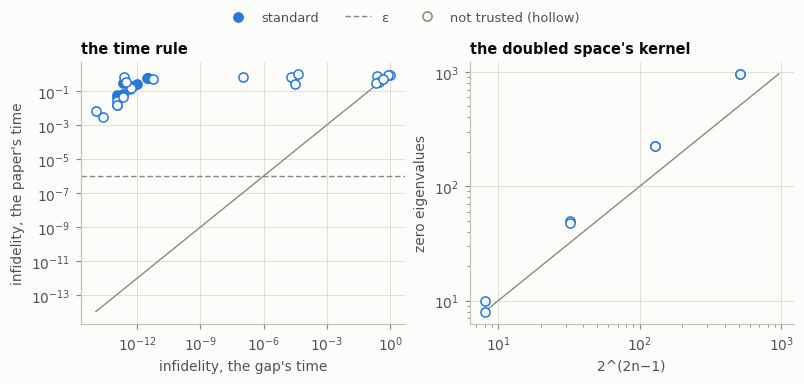

In [3]:
plotting.checks(
    [
        plotting.Check(
            {"standard": protocol},
            "gap_infidelity",
            "paper_infidelity",
            "infidelity, the gap's time",
            "infidelity, the paper's time",
            "the time rule",
            bar=epsilon,
            bar_label="ε",
        ),
        plotting.Check(
            {"standard": doubled},
            "paper_count",
            "kernel_count",
            "2^(2n−1)",
            "zero eigenvalues",
            "the doubled space's kernel",
        ),
    ]
);

**What this does not show.** The paper's circuits and its claim of efficient terms, which the test
suite checks rather than the records; the published encoder's cost is notebook 40's. The nonlinear
route that does prepare, the Carleman lift, is notebook 61's.